# Sesión 01 — Ciclo de Vida de Proyectos de Machine Learning
**Curso:** Ingeniería del Conocimiento (ISO56B)
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Alumno:** Sebastián Hurtado Pastrana
**Periodo:** 2026-II | Universidad Nacional del Centro del Perú

---

## Objetivo
Mismo ciclo de vida y mismas herramientas de la plantilla del curso, pero aplicado al dataset climático
de **Bengaluru** en vez de Heart Disease. Resuelve el **Ejercicio 2** (nuevo dataset, mismo pipeline) y el
**Ejercicio 3** (registro de experimentos con MLflow) juntos, al final del notebook.

## 1. Configuración del entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
import joblib

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

print('Entorno configurado correctamente.')

Entorno configurado correctamente.


---
## 2. Etapa 1 — Recolección de datos
Cargamos el dataset climático horario de **Bengaluru** (2009-2020).

| Variable | Descripción |
|---|---|
| `humidity` | Humedad relativa (%) |
| `pressure` | Presión atmosférica (hPa) |
| `cloudcover` | Cobertura de nubes (%) |
| `windspeedKmph` | Velocidad del viento (km/h) |
| `sunHour` | Horas de sol del día |
| `precipMM` | Precipitación (mm) |
| `tempC` | Temperatura horaria (°C) — usada para crear `target` |
| `target` | 1 = hora calurosa (tempC > mediana), 0 = hora fresca |

In [3]:
RUTA_LOCAL = 'data/bengaluru.csv'

try:
    df = pd.read_csv(RUTA_LOCAL)
    print(f'Dataset cargado — {df.shape[0]} registros, {df.shape[1]} columnas')
except Exception as e:
    print(f'Error al cargar el dataset: {e}')
    raise

df.head()

Dataset cargado — 96432 registros, 25 columnas


,date_time,maxtempC,mintempC,totalSnow_cm,sunHour,uvIndex,uvIndex.1,moon_illumination,moonrise,moonset,...,WindChillC,WindGustKmph,cloudcover,humidity,precipMM,pressure,tempC,visibility,winddirDegree,windspeedKmph
0,2009-01-01 00:00:00,27,12,0.0,11.6,5,1,31,09:58 AM,10:03 PM,...,18,11,2,91,0.0,1014,14,10,109,8
1,2009-01-01 01:00:00,27,12,0.0,11.6,5,1,31,09:58 AM,10:03 PM,...,17,9,2,93,0.0,1014,14,7,85,6
2,2009-01-01 02:00:00,27,12,0.0,11.6,5,1,31,09:58 AM,10:03 PM,...,16,7,2,94,0.0,1014,13,5,61,4
3,2009-01-01 03:00:00,27,12,0.0,11.6,5,1,31,09:58 AM,10:03 PM,...,15,5,2,96,0.0,1014,12,2,37,3
4,2009-01-01 04:00:00,27,12,0.0,11.6,5,1,31,09:58 AM,10:03 PM,...,18,5,1,88,0.0,1015,14,5,45,3


---
## 3. Etapa 2 — Exploración y preparación de datos

In [4]:
# 3.1  Información general del dataset
print('='*60)
print('INFORMACIÓN DEL DATASET')
print('='*60)
df.info()
print('\n')
df.describe().round(2)

INFORMACIÓN DEL DATASET
<class 'pandas.DataFrame'>
RangeIndex: 96432 entries, 0 to 96431
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   date_time          96432 non-null  str    
 1   maxtempC           96432 non-null  int64  
 2   mintempC           96432 non-null  int64  
 3   totalSnow_cm       96432 non-null  float64
 4   sunHour            96432 non-null  float64
 5   uvIndex            96432 non-null  int64  
 6   uvIndex.1          96432 non-null  int64  
 7   moon_illumination  96432 non-null  int64  
 8   moonrise           96432 non-null  str    
 9   moonset            96432 non-null  str    
 10  sunrise            96432 non-null  str    
 11  sunset             96432 non-null  str    
 12  DewPointC          96432 non-null  int64  
 13  FeelsLikeC         96432 non-null  int64  
 14  HeatIndexC         96432 non-null  int64  
 15  WindChillC         96432 non-null  int64  
 16  WindGustK

,maxtempC,mintempC,totalSnow_cm,sunHour,uvIndex,uvIndex.1,moon_illumination,DewPointC,FeelsLikeC,HeatIndexC,WindChillC,WindGustKmph,cloudcover,humidity,precipMM,pressure,tempC,visibility,winddirDegree,windspeedKmph
count,96432.00,96432.00,96432.0,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00,96432.00
mean,29.65,19.34,0.0,10.65,5.90,4.01,46.09,16.09,25.00,25.27,24.42,17.37,34.85,64.90,0.08,1010.55,23.98,9.27,176.18,12.45
std,3.45,2.77,0.0,1.99,0.85,2.87,31.25,4.16,4.59,4.43,4.52,7.43,28.39,21.86,0.39,3.19,4.54,2.18,89.44,5.72
min,18.00,11.00,0.0,4.20,4.00,1.00,0.00,-9.00,12.00,13.00,12.00,0.00,0.00,6.00,0.00,1000.00,0.00,0.00,0.00,0.00
25%,27.00,18.00,0.0,8.80,5.00,1.00,18.00,14.00,21.00,22.00,21.00,12.00,9.00,49.00,0.00,1008.00,21.00,10.00,94.00,8.00
50%,29.00,20.00,0.0,11.60,6.00,5.00,46.00,18.00,25.00,25.00,24.00,17.00,29.00,68.00,0.00,1010.00,23.00,10.00,163.00,12.00
75%,32.00,21.00,0.0,11.60,6.00,7.00,73.00,19.00,28.00,28.00,27.00,22.00,54.00,83.00,0.00,1013.00,27.00,10.00,262.00,16.00
max,40.00,28.00,0.0,12.90,8.00,10.00,100.00,25.00,43.00,43.00,42.00,53.00,100.00,100.00,16.90,1021.00,40.00,20.00,360.00,41.00


In [5]:
# 3.2  Valores nulos y duplicados
print('Valores nulos por columna:')
print(df.isnull().sum())
print(f'\nRegistros duplicados: {df.duplicated().sum()}')

df = df.drop_duplicates().reset_index(drop=True)
print(f'Registros después de limpieza: {df.shape[0]}')

Valores nulos por columna:
date_time            0
maxtempC             0
mintempC             0
totalSnow_cm         0
sunHour              0
uvIndex              0
uvIndex.1            0
moon_illumination    0
moonrise             0
moonset              0
sunrise              0
sunset               0
DewPointC            0
FeelsLikeC           0
HeatIndexC           0
WindChillC           0
WindGustKmph         0
cloudcover           0
humidity             0
precipMM             0
pressure             0
tempC                0
visibility           0
winddirDegree        0
windspeedKmph        0
dtype: int64

Registros duplicados: 0
Registros después de limpieza: 96432


In [6]:
# 3.3  tempC es continua, así que la convertimos en binaria (target) usando la mediana
mediana_temp = df['tempC'].median()
df['target'] = (df['tempC'] > mediana_temp).astype(int)
print(f'Mediana de tempC: {mediana_temp} °C  ->  target: 1=calurosa, 0=fresca')

Mediana de tempC: 23.0 °C  ->  target: 1=calurosa, 0=fresca


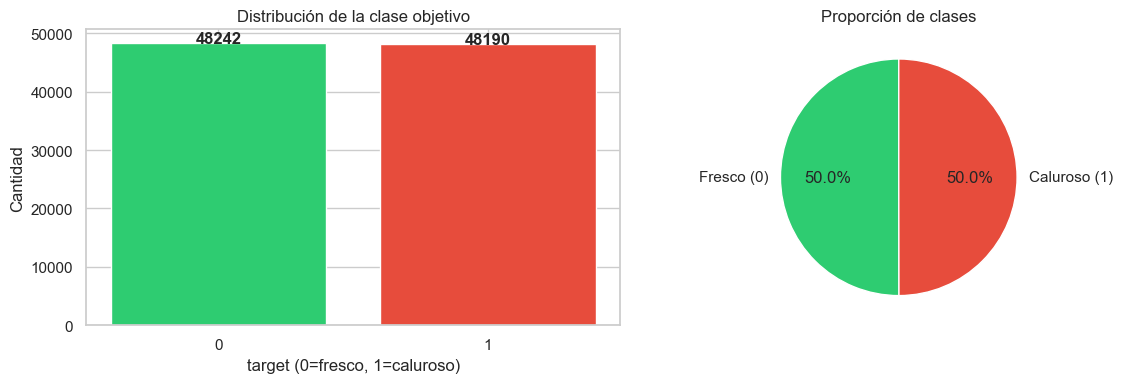

In [8]:
# 3.4  Distribución de la variable objetivo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Conteo
target_counts = df['target'].value_counts()
axes[0].bar(target_counts.index.astype(str), target_counts.values,
            color=['#2ecc71', '#e74c3c'])
axes[0].set_title('Distribución de la clase objetivo')
axes[0].set_xlabel('target (0=fresco, 1=caluroso)')
axes[0].set_ylabel('Cantidad')
for i, v in enumerate(target_counts.values):
    axes[0].text(i, v + 2, str(v), ha='center', fontweight='bold')

# Proporción
axes[1].pie(target_counts.values, labels=['Fresco (0)', 'Caluroso (1)'],
            autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'], startangle=90)
axes[1].set_title('Proporción de clases')

plt.tight_layout()
plt.show()

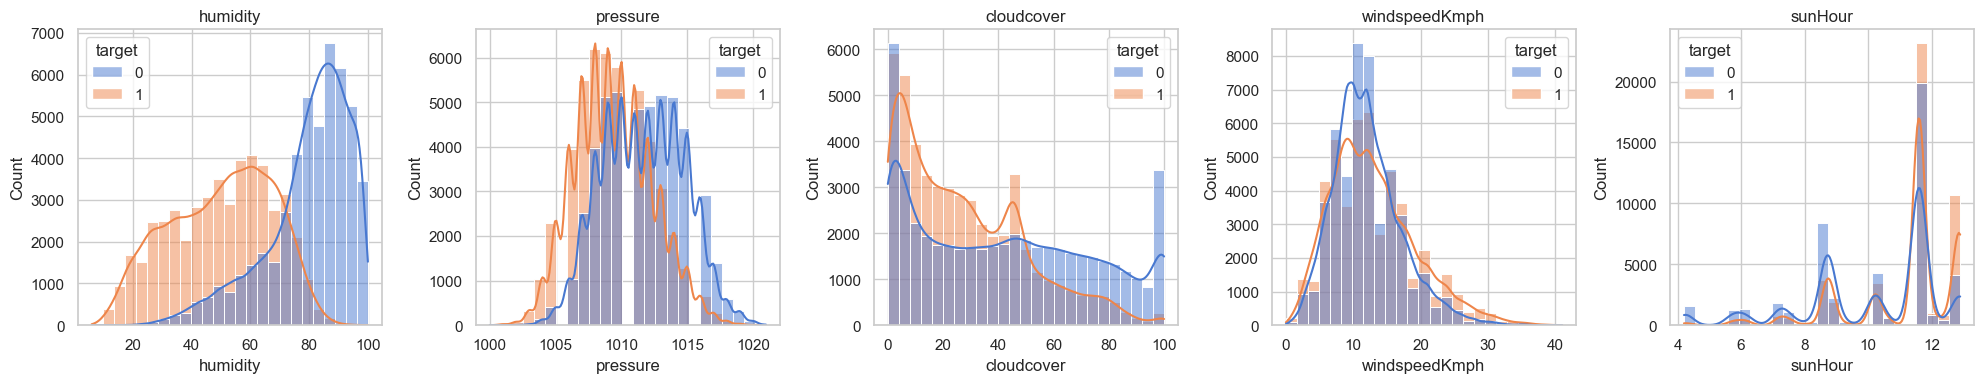

In [9]:
# 3.5  Distribución de variables numéricas clave
num_cols = ['humidity', 'pressure', 'cloudcover', 'windspeedKmph', 'sunHour']

fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue='target', kde=True, ax=ax, bins=25)
    ax.set_title(col)
plt.tight_layout()
plt.show()

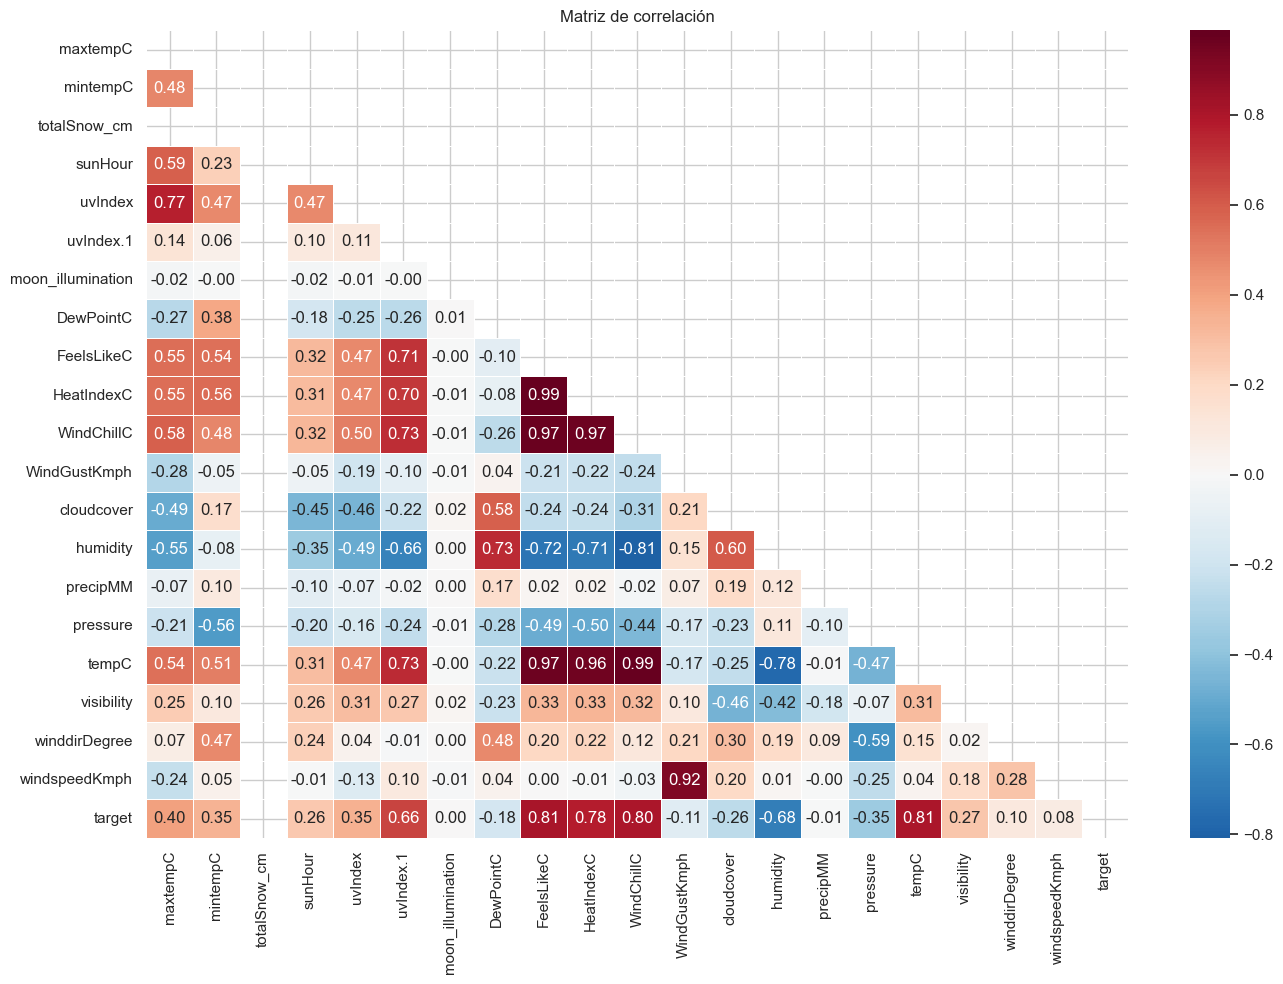

In [10]:
# 3.6  Matriz de correlación
cols_numericas = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(14, 10))
corr = df[cols_numericas].corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, linewidths=0.5)
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

---
## 4. Etapa 3 — Preparación de datos para el modelado

In [11]:
# 4.1  Separación de features y target
# Excluimos columnas de texto/fecha y las derivadas directamente de tempC (fuga de información)
columnas_fuga = ['tempC', 'maxtempC', 'mintempC', 'DewPointC', 'FeelsLikeC', 'HeatIndexC', 'WindChillC']
columnas_texto_fecha = ['date_time', 'moonrise', 'moonset', 'sunrise', 'sunset']

X = df.drop(columns=columnas_fuga + columnas_texto_fecha + ['target'])
y = df['target']

print(f'Features: {X.shape}')
print(f'Target:   {y.shape}')

Features: (96432, 13)
Target:   (96432,)


In [12]:
# 4.2  División train / test (80-20, estratificado)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'Train: {X_train.shape[0]} muestras')
print(f'Test:  {X_test.shape[0]} muestras')

Train: 77145 muestras
Test:  19287 muestras


---
## 5. Etapa 4 — Entrenamiento de modelos
Entrenamos tres modelos base mediante pipelines de Scikit-learn.

In [13]:
# 5.1  Definición de pipelines
pipelines = {
    'LogisticRegression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'DecisionTree': Pipeline([
        ('clf', DecisionTreeClassifier(max_depth=5, random_state=42))
    ]),
    'RandomForest': Pipeline([
        ('clf', RandomForestClassifier(n_estimators=200, max_depth=7, random_state=42))
    ])
}

# 5.2  Validación cruzada (5-fold)
results = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
    results[name] = scores
    print(f'{name:20s}  Accuracy CV: {scores.mean():.4f} ± {scores.std():.4f}')

LogisticRegression    Accuracy CV: 0.9000 ± 0.0017
DecisionTree          Accuracy CV: 0.9022 ± 0.0013
RandomForest          Accuracy CV: 0.9193 ± 0.0025


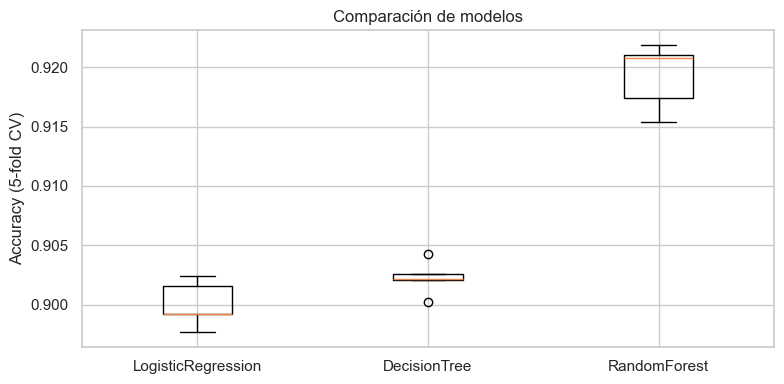

In [14]:
# 5.3  Comparación visual de modelos
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(results.values(), tick_labels=results.keys())
ax.set_ylabel('Accuracy (5-fold CV)')
ax.set_title('Comparación de modelos')
plt.tight_layout()
plt.show()

---
## 6. Etapa 5 — Evaluación del mejor modelo

In [15]:
# 6.1  Seleccionar el mejor modelo según CV y entrenar con todo el train set
best_name = max(results, key=lambda k: results[k].mean())
best_pipeline = pipelines[best_name]
best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)

print(f'Mejor modelo: {best_name}')
print(f'Accuracy en test: {best_pipeline.score(X_test, y_test):.4f}\n')
print(classification_report(y_test, y_pred, target_names=['Fresco', 'Caluroso']))

Mejor modelo: RandomForest
Accuracy en test: 0.9186

              precision    recall  f1-score   support

      Fresco       0.90      0.94      0.92      9649
    Caluroso       0.93      0.90      0.92      9638

    accuracy                           0.92     19287
   macro avg       0.92      0.92      0.92     19287
weighted avg       0.92      0.92      0.92     19287



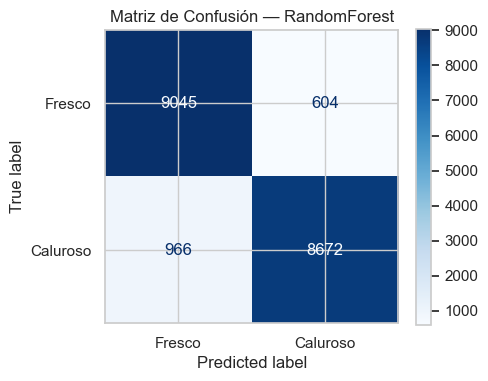

In [16]:
# 6.2  Matriz de confusión
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Fresco', 'Caluroso'], cmap='Blues', ax=ax
)
ax.set_title(f'Matriz de Confusión — {best_name}')
plt.tight_layout()
plt.show()

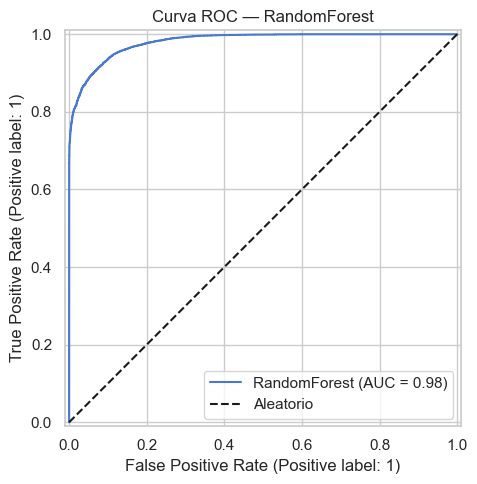

In [17]:
# 6.3  Curva ROC
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(best_pipeline, X_test, y_test, ax=ax, name=best_name)
ax.plot([0, 1], [0, 1], 'k--', label='Aleatorio')
ax.set_title(f'Curva ROC — {best_name}')
ax.legend()
plt.tight_layout()
plt.show()

---
## 7. Etapa 6 — Serialización y despliegue conceptual
Guardamos el pipeline entrenado con `joblib`.

In [18]:
# 7.1  Guardar el modelo
MODEL_PATH = 'temperatura_bengaluru_model.joblib'
joblib.dump(best_pipeline, MODEL_PATH)
print(f'Modelo guardado en: {MODEL_PATH}')

Modelo guardado en: temperatura_bengaluru_model.joblib


In [19]:
# 7.2  Cargar y verificar el modelo serializado
loaded_model = joblib.load(MODEL_PATH)
assert np.array_equal(loaded_model.predict(X_test), y_pred), 'Las predicciones no coinciden'
print('Verificación OK: el modelo cargado reproduce las predicciones.')

Verificación OK: el modelo cargado reproduce las predicciones.


In [20]:
# 7.3  Función de inferencia (simula un endpoint de predicción)

def predict_temperatura(clima_data: dict) -> dict:
    '''Recibe las variables climáticas de una hora y retorna si se predice
    una hora calurosa o fresca, con su probabilidad.'''
    model = joblib.load(MODEL_PATH)
    columnas = list(X.columns)

    try:
        valores = [clima_data[col] for col in columnas]
        input_df = pd.DataFrame([valores], columns=columnas)
    except KeyError as e:
        raise ValueError(f"Falta la variable {e}. Se esperan: {columnas}")

    pred = model.predict(input_df)[0]
    proba = model.predict_proba(input_df)[0]

    return {
        'prediccion': 'Caluroso' if pred == 1 else 'Fresco',
        'probabilidad_caluroso': round(float(proba[1]), 4),
        'probabilidad_fresco': round(float(proba[0]), 4)
    }

hora_ejemplo = {
    'totalSnow_cm': 0.0, 'sunHour': 9.5, 'uvIndex': 6, 'uvIndex.1': 6,
    'moon_illumination': 40, 'WindGustKmph': 15, 'cloudcover': 20,
    'humidity': 55, 'precipMM': 0.0, 'pressure': 1013,
    'visibility': 10, 'winddirDegree': 120, 'windspeedKmph': 10
}

print(predict_temperatura(hora_ejemplo))

{'prediccion': 'Fresco', 'probabilidad_caluroso': 0.4349, 'probabilidad_fresco': 0.5651}


---
## 8. Resumen del ciclo de vida

| Etapa | Qué hicimos |
|---|---|
| Recolección | Carga del dataset climático de Bengaluru |
| Exploración | Distribuciones, correlaciones, construcción del `target` |
| Preparación | Limpieza, exclusión de columnas con fuga de información, split 80/20 |
| Entrenamiento | 3 modelos con pipelines + validación cruzada 5-fold |
| Evaluación | Accuracy, classification report, matriz de confusión, ROC |
| Despliegue | Serialización con joblib + función de inferencia |

---
## 9. Ejercicios 2 y 3 nueva dataset

In [21]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('prediccion_temperatura_bengaluru')

for nombre, pipe in pipelines.items():
    with mlflow.start_run(run_name=nombre):
        mlflow.log_param('modelo', nombre)
        mlflow.log_metric('accuracy_cv', results[nombre].mean())

with mlflow.start_run(run_name=f'{best_name}_final'):
    mlflow.log_param('modelo', best_name)
    mlflow.log_metric('accuracy_test', best_pipeline.score(X_test, y_test))
    mlflow.sklearn.log_model(best_pipeline, artifact_path='modelo', serialization_format='pickle')

print('Experimentos registrados en mlflow.db')

2026/09/19 22:11:22 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/09/19 22:11:22 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Experimentos registrados en mlflow.db


In [22]:
# Para revisarlo visualmente (en una terminal, no aquí):
# mlflow ui --backend-store-uri sqlite:///mlflow.db
runs_df = mlflow.search_runs(experiment_names=['prediccion_temperatura_bengaluru'])
runs_df[['tags.mlflow.runName', 'metrics.accuracy_cv', 'metrics.accuracy_test']]

,tags.mlflow.runName,metrics.accuracy_cv,metrics.accuracy_test
0,RandomForest_final,NaN,0.918598
1,RandomForest,0.919295,NaN
2,DecisionTree,0.902249,NaN
3,LogisticRegression,0.900006,NaN
4,RandomForest_final,NaN,0.918598
5,RandomForest,0.919295,NaN
6,DecisionTree,0.902249,NaN
7,LogisticRegression,0.900006,NaN
8,randomforest_tuned_gridsearch,NaN,NaN
9,baseline_RandomForest,NaN,NaN
